# Data Exploration

Import Libraries

In [28]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Load the JSON and inspect the first sweep

In [29]:
current = Path.cwd().resolve()
project_root = next(
    path for path in (current, *current.parents)
    if (path / "pyproject.toml").is_file()
)

data_path = project_root / "data" / "raw" / "N45B-nmos1.json"

with data_path.open(encoding="utf-8") as file:
    mesd = json.load(file)

sweeps = pd.DataFrame(mesd["Records"])

print({key: value for key, value in mesd.items() if key != "Records"})
print(f"Number of sweeps = {len(sweeps):,}")

columns = ["W", "L", "Temp", "Corner", "Vds", "Vgs", "Ids"]
display(sweeps.loc[[0], columns])

{'PDK': 'N45B', 'Node': 45, 'Model': 'BSIM4.3', 'Device': 'nmos1', 'Type': 'NMOS', 'Simulator': 'spectre'}
Number of sweeps = 9,000


,W,L,Temp,Corner,Vds,Vgs,Ids
0,120,60,-40,tt,0.0,"[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, ...","[0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0..."


Making one row per operating point 

In [30]:
df = (
    sweeps[columns]
    .rename_axis("sweep_id")
    .explode(["Vgs", "Ids"])
    .reset_index()
    .astype({"Vgs": float, "Ids": float})
)

print(f"Number of operating points = {len(df):,}")
display(df.head())

summary = df[columns].describe(include="all").T
summary["missing"] = df[columns].isna().sum()
summary["unique_values"] = df[columns].nunique()
display(summary[["unique_values", "missing", "min", "max"]])

Number of operating points = 99,000


,sweep_id,W,L,Temp,Corner,Vds,Vgs,Ids
0,0,120,60,-40,tt,0.0,0.0,1.059800e-48
1,0,120,60,-40,tt,0.0,0.1,-1.635900e-15
2,0,120,60,-40,tt,0.0,0.2,-8.017000e-15
3,0,120,60,-40,tt,0.0,0.3,-2.346700e-14
4,0,120,60,-40,tt,0.0,0.4,-6.148500e-14


,unique_values,missing,min,max
W,10,0,120.0,1000.0
L,10,0,60.0,1000.0
Temp,5,0,-40.0,125.0
Corner,3,0,NaN,NaN
Vds,6,0,0.0,1.0
Vgs,11,0,0.0,1.0
Ids,87960,0,-0.0,0.000565


Audit the voltage sweeps

In [31]:
positive_bias_sweeps = sweeps.loc[sweeps["Vds"] > 0].copy()
curve_signatures = [
    (tuple(vgs), tuple(ids))
    for vgs, ids in zip(positive_bias_sweeps["Vgs"], positive_bias_sweeps["Ids"], strict=True)
]
duplicate_sweeps = len(curve_signatures) - len(set(curve_signatures))

corner_currents = (
    positive_bias_sweeps.assign(
        on_current=positive_bias_sweeps["Ids"].map(lambda values: values[-1])
    )
    .pivot(index=["W", "L", "Temp", "Vds"], columns="Corner", values="on_current")
)
ordered = (corner_currents["ff"] > corner_currents["tt"]) & (
    corner_currents["tt"] > corner_currents["ss"]
)

print(f"Positive-bias sweeps = {len(positive_bias_sweeps):,}")
print(f"Exact repeats beyond the first occurrence = {duplicate_sweeps:,}")
print(f"Matched conditions with ff > tt > ss = {ordered.sum():,} / {len(ordered):,}")

nonpositive = df.loc[df["Ids"] <= 0]
print(f"Nonpositive currents at zero drain bias = {nonpositive['Vds'].eq(0).sum():,}")
print(f"Nonpositive currents at positive drain bias = {nonpositive['Vds'].gt(0).sum():,}")

Positive-bias sweeps = 7,500
Exact repeats beyond the first occurrence = 0
Matched conditions with ff > tt > ss = 2,500 / 2,500
Nonpositive currents at zero drain bias = 16,490
Nonpositive currents at positive drain bias = 0


Plot drain current on a linear scale

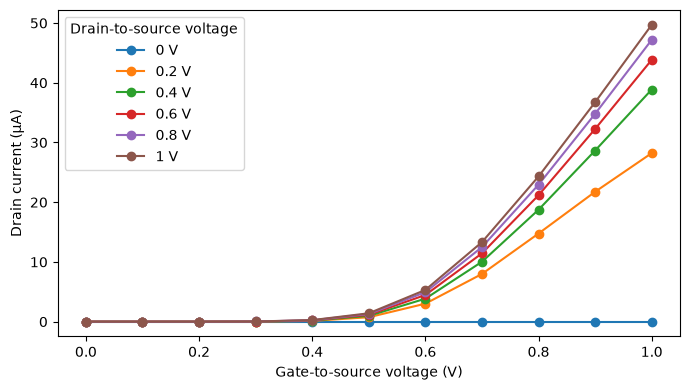

In [32]:
curves = df.query("W == 120 and L == 60 and Temp == 25 and Corner == 'tt'")

fig, ax = plt.subplots(figsize=(7, 4))

for vds, curve in curves.sort_values("Vgs").groupby("Vds"):
    ax.plot(curve["Vgs"], curve["Ids"] * 1e6, marker="o", label=f"{vds:g} V")

ax.set(
    xlabel="Gate-to-source voltage (V)",
    ylabel="Drain current (µA)",
)
ax.legend(title="Drain-to-source voltage")
fig.tight_layout()
plt.show()

Plot drain current on a logarithmic scale

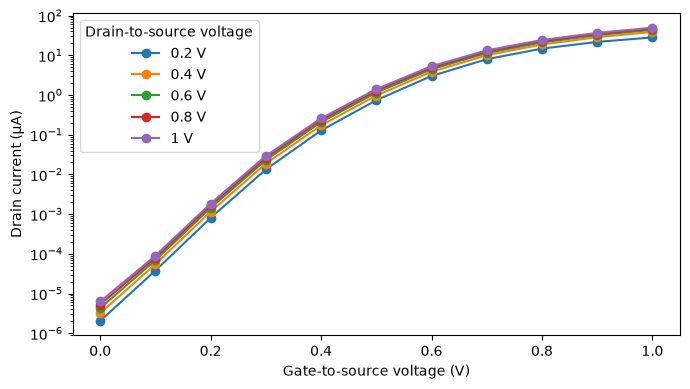

In [33]:
log_curves = curves.loc[(curves["Vds"] > 0) & (curves["Ids"] > 0)]

fig, ax = plt.subplots(figsize=(7, 4))
for vds, curve in log_curves.sort_values("Vgs").groupby("Vds"):
    ax.plot(curve["Vgs"], curve["Ids"] * 1e6, marker="o", label=f"{vds:g} V")

ax.set(
    yscale="log",
    xlabel="Gate-to-source voltage (V)",
    ylabel="Drain current (µA)",
)
ax.legend(title="Drain-to-source voltage")
fig.tight_layout()
plt.show()

# Preprocessing

Build the modeling table

In [34]:
current = Path.cwd().resolve()
project_root = next(
    path for path in (current, *current.parents)
    if (path / "pyproject.toml").is_file()
)
raw_path = project_root / "data" / "raw" / "N45B-nmos1.json"

#open the raw data file and load the JSON content
with raw_path.open(encoding="utf-8") as file:
    mesd = json.load(file)

columns = ["W", "L", "Temp", "Corner", "Vds", "Vgs", "Ids"]


points = (
    pd.DataFrame(mesd["Records"])[columns]
    .rename_axis("sweep_id")
    .explode(["Vgs", "Ids"])
    .reset_index()
    .astype({"Vgs": float, "Ids": float})
)

df = points.loc[points["Vds"] > 0].copy().reset_index(drop=True)
assert np.isfinite(df["Ids"]).all() and df["Ids"].gt(0).all()

df["log10_Ids"] = np.log10(df["Ids"])

print(f"Raw operating points: {len(points):,}")
print(f"Positive-drain-bias points: {len(df):,}")
print(f"Positive-drain-bias sweeps: {df['sweep_id'].nunique():,}")
print(f"log10(Ids) range: {df['log10_Ids'].min():.2f} to {df['log10_Ids'].max():.2f}")
display(df.head())

Raw operating points: 99,000
Positive-drain-bias points: 82,500
Positive-drain-bias sweeps: 7,500
log10(Ids) range: -12.39 to -3.25


,sweep_id,W,L,Temp,Corner,Vds,Vgs,Ids,log10_Ids
0,1,120,60,-40,tt,0.2,0.0,4.710100e-13,-12.326970
1,1,120,60,-40,tt,0.2,0.1,3.849100e-12,-11.414641
2,1,120,60,-40,tt,0.2,0.2,1.758100e-10,-9.754956
3,1,120,60,-40,tt,0.2,0.3,5.683300e-09,-8.245399
4,1,120,60,-40,tt,0.2,0.4,6.878800e-08,-7.162487


Fix and verify the held-out-width split

In [35]:
#split the dataset into training and testing sets based on unique widths
test_widths = [243, 624]
assert set(test_widths).issubset(df["W"].unique())

df["split"] = np.where(df["W"].isin(test_widths), "test", "train")

train = df.loc[df["split"].eq("train")]
test = df.loc[df["split"].eq("test")]

assert set(train["W"]).isdisjoint(test["W"])
assert set(train["sweep_id"]).isdisjoint(test["sweep_id"])

display(
    df.groupby("split").agg(
        rows=("Ids", "size"),
        sweeps=("sweep_id", "nunique"),
        widths=("W", "nunique"),
    )
)

#save the processed dataset to a CSV file
processed_path = project_root / "data" / "processed" / "n45b_nmos1_iv.csv"
processed_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(processed_path, index=False)

,rows,sweeps,widths
split,,,
test,16500,1500,2
train,66000,6000,8


# Model: Linear Regression

Load Processed dataset

In [36]:
current = Path.cwd().resolve()
project_root = next(
    path for path in (current, *current.parents)
    if (path / "pyproject.toml").is_file()
)

csv_path = project_root / "data" / "processed" / "n45b_nmos1_iv.csv"
df = pd.read_csv(csv_path)

train = df.loc[df["split"].eq("train")].reset_index(drop=True)

numeric_features = ["Vgs", "Vds", "W", "L", "Temp"]
features = numeric_features + ["Corner"]

X = train[features]
y = train["Ids"]
groups = train["W"]

print(f"Training rows: {len(train):,}")
print(f"Training widths (nm): {sorted(groups.unique().tolist())}")
display(X[numeric_features].corr().round(3))

Training rows: 66,000
Training widths (nm): [120, 152, 192, 308, 390, 493, 790, 1000]


,Vgs,Vds,W,L,Temp
Vgs,1.0,-0.0,-0.0,-0.0,-0.0
Vds,-0.0,1.0,-0.0,-0.0,-0.0
W,-0.0,-0.0,1.0,-0.0,-0.0
L,-0.0,-0.0,-0.0,1.0,0.0
Temp,-0.0,-0.0,-0.0,0.0,1.0


Import necessary libraries for Linear Regression

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, cross_validate

Build Linear Regression pipeline

In [38]:
preprocess = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("corner", OneHotEncoder(drop="first"), ["Corner"]),
])

linear_model = make_pipeline(preprocess, LinearRegression())

Validate on whole widths

In [39]:
folds = list(GroupKFold(n_splits=4).split(X, y, groups=groups))

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

models = {
    "Training mean": DummyRegressor(strategy="mean"),
    "Linear regression": linear_model,
}

results = []

for name, model in models.items():
    scores = cross_validate(model, X, y, cv=folds, scoring=scoring)

    results.append(pd.DataFrame({
        "model": name,
        "validation_widths_nm": [
            sorted(groups.iloc[val_idx].unique().tolist())
            for _, val_idx in folds
        ],
        "MAE_uA": -scores["test_mae"] * 1e6,
        "RMSE_uA": -scores["test_rmse"] * 1e6,
    }))

results = pd.concat(results, ignore_index=True)
display(results.round(2))
display(results.groupby("model")[["MAE_uA", "RMSE_uA"]].mean().round(2))

,model,validation_widths_nm,MAE_uA,RMSE_uA
0,Training mean,"[308, 1000]",30.60,57.68
1,Training mean,"[192, 790]",25.82,44.55
2,Training mean,"[152, 493]",21.29,29.23
3,Training mean,"[120, 390]",20.20,25.00
4,Linear regression,"[308, 1000]",24.77,42.97
5,Linear regression,"[192, 790]",19.86,32.20
6,Linear regression,"[152, 493]",16.43,21.55
7,Linear regression,"[120, 390]",16.85,20.61


,MAE_uA,RMSE_uA
model,,
Linear regression,19.48,29.33
Training mean,24.48,39.12


### Linear Regression - Out-of-Fold Predictions

In [40]:
from sklearn.base import clone

#Store predictions for every training observation
oof_predictions = np.full(len(y), np.nan)

for train_idx, val_idx in folds:
    #Create a fresh copy of the model
    model = clone(linear_model)

    #Train using only the training portion of this fold
    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    #Predict on the validation portion
    oof_predictions[val_idx] = model.predict(
        X.iloc[val_idx]
    )

assert np.isfinite(oof_predictions).all()

print("Actual values:", len(y))
print("Predictions:", len(oof_predictions))


Actual values: 66000
Predictions: 66000


### Actual vs. Predicted Drain Current

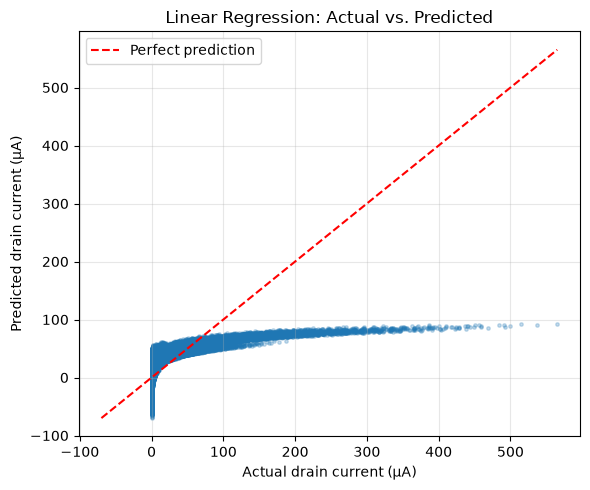

In [41]:
#convert current from amperes to microamperes
#actual is the true drain current and predicted is the model's prediction of the drain current
actual_uA = y.to_numpy() * 1e6
predicted_uA = oof_predictions * 1e6

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    actual_uA,
    predicted_uA,
    s=6,
    alpha=0.25
)

#ideal prediction line
low = min(actual_uA.min(), predicted_uA.min())
high = max(actual_uA.max(), predicted_uA.max())

ax.plot(
    [low, high],
    [low, high],
    "r--",
    label="Perfect prediction"
)

ax.set(
    xlabel="Actual drain current (µA)",
    ylabel="Predicted drain current (µA)",
    title="Linear Regression: Actual vs. Predicted"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Calculating Residuals

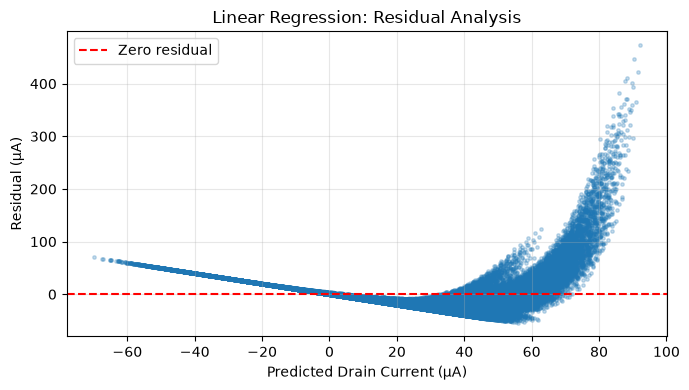

In [42]:
#Calculate residuals for model evaluation
residuals_uA = actual_uA - predicted_uA

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    predicted_uA,
    residuals_uA,
    s=6,
    alpha=0.25
)

#reference line for perfect predictions
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero residual"
)

ax.set(
    xlabel="Predicted Drain Current (µA)",
    ylabel="Residual (µA)",
    title="Linear Regression: Residual Analysis"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
print("Available widths:", sorted(train["W"].unique()))
print("Available lengths:", sorted(train["L"].unique()))
print("Available temperatures:", sorted(train["Temp"].unique()))
print("Available corners:", train["Corner"].unique())
print("Available Vds:", sorted(train["Vds"].unique()))

Available widths: [np.int64(120), np.int64(152), np.int64(192), np.int64(308), np.int64(390), np.int64(493), np.int64(790), np.int64(1000)]
Available lengths: [np.int64(60), np.int64(82), np.int64(112), np.int64(153), np.int64(210), np.int64(286), np.int64(391), np.int64(535), np.int64(732), np.int64(1000)]
Available temperatures: [np.int64(-40), np.int64(0), np.int64(25), np.int64(85), np.int64(125)]
Available corners: <StringArray>
['tt', 'ss', 'ff']
Length: 3, dtype: str
Available Vds: [np.float64(0.2), np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0)]


### Compare simulated and predicted drain current

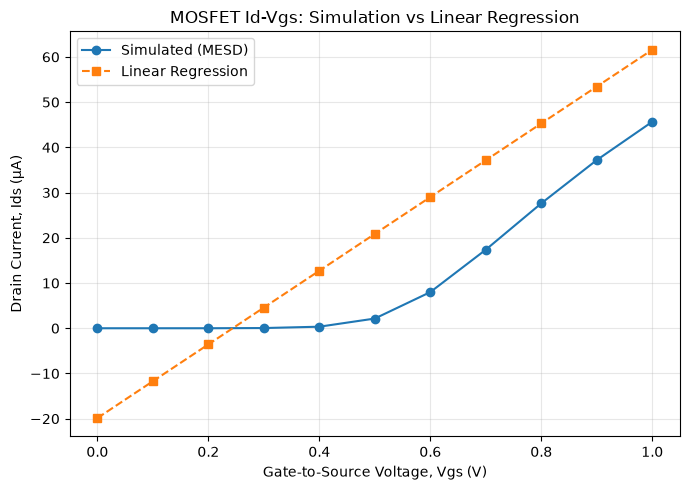

Selected configuration:
{'W': np.int64(120), 'L': np.int64(60), 'Temp': np.int64(-40), 'Corner': 'ff', 'Vds': np.float64(0.2)}
Number of Vgs points: 11


In [44]:
#combine actual and out-of-fold predicted currents
plot_df = train.copy()
plot_df["predicted_Ids"] = oof_predictions

#identify available transistor configurations
fixed_cols = ["W", "L", "Temp", "Corner", "Vds"]

#choose a sweep with the largest number of Vgs points
sweep_counts = (
    plot_df[plot_df["Vds"] > 0]
    .groupby(fixed_cols)["Vgs"]
    .nunique()
    .sort_values(ascending=False)
)

selected = sweep_counts.index[0]

#extract the selected sweep
curve = plot_df.copy()

for col, value in zip(fixed_cols, selected):
    curve = curve[curve[col] == value]

curve = curve.sort_values("Vgs")

#plot simulated vs predicted current
plt.figure(figsize=(7, 5))

plt.plot(
    curve["Vgs"],
    curve["Ids"] * 1e6,
    "o-",
    label="Simulated (MESD)"
)

plt.plot(
    curve["Vgs"],
    curve["predicted_Ids"] * 1e6,
    "s--",
    label="Linear Regression"
)

plt.xlabel("Gate-to-Source Voltage, Vgs (V)")
plt.ylabel("Drain Current, Ids (µA)")
plt.title("MOSFET Id-Vgs: Simulation vs Linear Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Selected configuration:")
print(dict(zip(fixed_cols, selected)))
print("Number of Vgs points:", len(curve))

### Observations of the Linear Regression

The Actual vs. Predicted plot shows that Linear Regression significantly underpredicts high drain currents with predictions having a narrow range. The residual plot shows a clear nonlinear pattern, indicating systematic prediction errors.

Moreover, the Id vs Vgs comparison shows that the simulated drain current increases nonlinearly with gate voltage. Linear Regression predicts negative currents at low gate voltages and overestimates current at higher gate voltages.

So, Linear Regression cannot adequately capture the nonlinear relationship between MOSFET operating conditions and drain current.

### Evaluation Metrics for Model Comparison (Function)

In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def current_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # Raw-current metrics (all predictions included)
    mae_uA = mean_absolute_error(y_true, y_pred) * 1e6
    rmse_uA = np.sqrt(
        mean_squared_error(y_true, y_pred)
    ) * 1e6

    # Percentage of physically invalid predictions
    nonpositive_pct = 100 * np.mean(y_pred <= 0)

    results = {
        "MAE_uA": mae_uA,
        "RMSE_uA": rmse_uA,
        "nonpositive_pct": nonpositive_pct,
        "RMSE_decades": np.nan,
        "median_err_factor": np.nan,
    }

    # Log metrics are valid only when ALL currents are positive
    if np.all(y_true > 0) and np.all(y_pred > 0):
        log_error = np.log10(y_pred) - np.log10(y_true)

        results["RMSE_decades"] = np.sqrt(
            np.mean(log_error**2)
        )

        results["median_err_factor"] = 10 ** (
            np.median(np.abs(log_error))
        )

    return results


# Model: Polynomial Regression 

Import necessasry Libraries

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    PolynomialFeatures,
    StandardScaler,
    OneHotEncoder
)
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

## Polynomial Regression - Degree Comparison

In [60]:
#create logarithmic geometry features
train["log_W"] = np.log10(train["W"])
train["log_L"] = np.log10(train["L"])

#updated numerical features for polynomial regression
log_numeric = [
    "Vgs",
    "Vds",
    "log_W",
    "log_L",
    "Temp"
]

cols = log_numeric + ["Corner"]

#function to create a polynomial regression model with specified degree
def make_poly(degree):
    preprocess = ColumnTransformer([
        ("numeric", StandardScaler(), log_numeric),
        ("corner", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ), ["Corner"]),
    ])

    return make_pipeline(
        preprocess,
        PolynomialFeatures(
            degree=degree,
            include_bias=False
        ),
        LinearRegression()
    )

print("Polynomial Regression input features:", cols)

Polynomial Regression input features: ['Vgs', 'Vds', 'log_W', 'log_L', 'Temp', 'Corner']


### Train polynomial models from degree 1 to 6

In [61]:
#store out-of-fold predictions for each degree
oof_poly = {}
results = []

for degree in range(1, 7):

    predictions = np.full(len(train), np.nan)
    fold_train_errors = []

    for fit_idx, val_idx in folds:
        fit = train.iloc[fit_idx]
        val = train.iloc[val_idx]

        model = make_poly(degree)

        model.fit(
            fit[cols],
            fit["log10_Ids"]
        )

        # Training predictions
        train_pred = model.predict(fit[cols])

        train_rmse = np.sqrt(
            np.mean(
                (train_pred - fit["log10_Ids"].to_numpy()) ** 2
            )
        )

        fold_train_errors.append(train_rmse)

        # Validation predictions
        predictions[val_idx] = model.predict(val[cols])

    assert np.isfinite(predictions).all()

    oof_poly[degree] = predictions

    # Compute overall out-of-fold validation error
    val_rmse = np.sqrt(
        np.mean(
            (
                predictions -
                train["log10_Ids"].to_numpy()
            ) ** 2
        )
    )

    results.append({
        "degree": degree,
        "train_RMSE_decades": np.mean(fold_train_errors),
        "val_RMSE_decades": val_rmse,
        "median_error_factor": 10 ** np.median(
            np.abs(
                predictions -
                train["log10_Ids"].to_numpy()
            )
        )
    })

poly_results = pd.DataFrame(results)

display(poly_results.round(4))

,degree,train_RMSE_decades,val_RMSE_decades,median_error_factor
0,1,0.8119,0.8131,4.7067
1,2,0.1910,0.1927,1.3141
2,3,0.1525,0.1530,1.1988
3,4,0.0962,0.0966,1.1037
4,5,0.0562,0.0567,1.0654
5,6,0.0315,0.0423,1.0476


### Visualize polynomial degree vs error

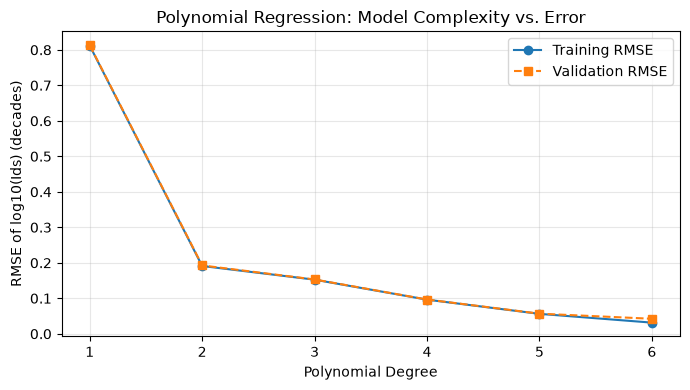

In [62]:
plt.figure(figsize=(7, 4))

plt.plot(
    poly_results["degree"],
    poly_results["train_RMSE_decades"],
    "o-",
    label="Training RMSE"
)

plt.plot(
    poly_results["degree"],
    poly_results["val_RMSE_decades"],
    "s--",
    label="Validation RMSE"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE of log10(Ids) (decades)")
plt.title("Polynomial Regression: Model Complexity vs. Error")

plt.xticks(poly_results["degree"])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Compare errors by transistor width

In [63]:
#per width RMSE for each polynomial degree using transistor width as the grouping variable
per_width_rmse = pd.DataFrame({
    f"Degree {degree}": (
        train.assign(
            squared_error=(
                predictions -
                train["log10_Ids"].to_numpy()
            ) ** 2
        )
        .groupby("W")["squared_error"]
        .mean() ** 0.5
    )
    for degree, predictions in oof_poly.items()
})

per_width_rmse.index.name = "Validation Width (nm)"

display(per_width_rmse.round(4))

,Degree 1,Degree 2,Degree 3,Degree 4,Degree 5,Degree 6
Validation Width (nm),,,,,,
120,0.8092,0.2128,0.1658,0.1064,0.0609,0.0411
152,0.8020,0.1953,0.1570,0.1002,0.0568,0.0324
192,0.8000,0.1888,0.1536,0.0971,0.0552,0.0310
308,0.8067,0.1867,0.1512,0.0947,0.0551,0.0310
390,0.8100,0.1854,0.1499,0.0937,0.0549,0.0307
493,0.8151,0.1861,0.1492,0.0934,0.0555,0.0312
790,0.8268,0.1892,0.1479,0.0929,0.0567,0.0321
1000,0.8348,0.1954,0.1488,0.0935,0.0583,0.0820


### Observations - Polynomial Regression

Polynomial Regression significantly improves prediction performance compared with the degree-1 model. Using logarithmic transistor dimensions log_W and log_L instead of raw dimensions (W and L) improves model accuracy and stability. As the polynomial degree increases from 1 to 6, validation RMSE decreases from **0.8131 to 0.0423 decades**, with a median multiplicative error factor of **1.0476** at degree 6. The training and validation errors remain relatively close, indicating good generalization across most validation widths.

However, the degree-6 model shows a higher error at the largest width (1000 nm), suggesting sensitivity to extrapolation beyond the training range. So, degree 6 Polynomial Regression with logarithmic geometry features achieves the best validation performance among the tested models. Ridge regularization will be investigated next to determine whether it can improve stability and generalization.